### Кейс 7 Прогнозирование энергопотребления бытовой техники

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

df = pd.read_csv("../data/energydata_complete.csv")

####  Загрузка и первичный осмотр

In [2]:
rooms = {
    1: 'Кухня', 
    2: 'Гостиная', 
    3: 'Прачечная', 
    4: 'Кабинет', 
    5: 'Ванная',
    6: 'Снаружи (северная сторона)', 
    7: 'Гладильная', 
    8: 'Комната подростка', 
    9: 'Комната родителей'
}
indoor = {i: room for i, room in rooms.items() if i != 6} 
station = 'Метеостанция в Шьевре'

features = {
    'date':        ('Дата и время записи (шаг 10 мин)', '—', '—'),
    'Appliances':  ('Энергопотребление бытовой техники — ЦЕЛЕВАЯ', 'Дом', 'Wh за 10мин'),
    'lights':      ('Энергопотребление освещения', 'Дом', 'Wh за 10мин'),
    'T_out':       ('Температура на улице', station, '°C'),
    'Press_mm_hg': ('Атмосферное давление', station, 'мм рт.ст.'),
    'RH_out':      ('Влажность на улице', station, '%'),
    'Windspeed':   ('Скорость ветра', station, 'м/с'),
    'Visibility':  ('Видимость', station, 'км'),
    'Tdewpoint':   ('Точка росы', station, '°C'),
    'rv1':         ('Случайная величина (шум)', '—', 'безразм.'),
    'rv2':         ('Случайная величина (шум)', '—', 'безразм.'),
}

for i, room in rooms.items():  # в каждой комнате есть данные по температуре и влажности
    features[f'T{i}'] = ('Температура', room, '°C')
    features[f'RH_{i}'] = ('Влажность', room, '%')

info = pd.DataFrame(
    [(col, *features.get(col, ('Нет описания', '—', '—'))) for col in df.columns],  # в каждой строке 3 столбца, если данных нет, дефолтный "—"
    columns=['Столбец', 'Description', 'Location', 'Units'],
).set_index('Столбец')

num = df.select_dtypes('number')
info['type'] = df.dtypes.astype(str)
info['unique'] = df.nunique()
info['min'] = num.min().round(2)
info['median'] = num.median().round(2)
info['max'] = num.max().round(2)

info.fillna('—')

,Description,Location,Units,type,unique,min,median,max
Столбец,,,,,,,,
date,Дата и время записи (шаг 10 мин),—,—,str,19735,—,—,—
Appliances,Энергопотребление бытовой техники — ЦЕЛЕВАЯ,Дом,Wh за 10мин,int64,92,10.0,60.0,1080.0
lights,Энергопотребление освещения,Дом,Wh за 10мин,int64,8,0.0,0.0,70.0
T1,Температура,Кухня,°C,float64,722,16.79,21.6,26.26
RH_1,Влажность,Кухня,%,float64,2547,27.02,39.66,63.36
T2,Температура,Гостиная,°C,float64,1650,16.1,20.0,29.86
RH_2,Влажность,Гостиная,%,float64,3376,20.46,40.5,56.03
T3,Температура,Прачечная,°C,float64,1426,17.2,22.1,29.24
RH_3,Влажность,Прачечная,%,float64,2618,28.77,38.53,50.16


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9           19

Пропущенных значений(Nan) нет

Общее кол-во строк 19735

Столбцов 29

Необходимо преобразовать тип столбца date

In [4]:
df['date'] = pd.to_datetime(df['date'])

In [5]:
# Проверка временного ряда: период, шаг, пропуски и дубли меток времени
start, end = df['date'].min().strftime('%d %b %Y %H:%M'), df['date'].max().strftime('%d %b %Y %H:%M')
print(f'Даты от {start} до {end}')
print('Отсортировано по времени:', df['date'].is_monotonic_increasing)
print('Дублей меток времени:', df['date'].duplicated().sum())
print('Полных дублей строк:', df.duplicated().sum())
print('Шаги между соседними записями:', df['date'].diff().value_counts().to_string(header=False))  # ожидается на 1 меньше, потому что у первой разница NaT

expected = pd.date_range(df['date'].min(), df['date'].max(), freq='10min')
missing = expected.difference(df['date'])
print(f'\nОжидается записей: {len(expected)} | есть: {len(df)} | пропущено меток: {len(missing)}\n')

counts = df['date'].dt.to_period('M').value_counts().sort_index()
full = counts.index.days_in_month * 24 * 6        # days in month * 24 hours * 6 10-min-timeslots per hour 
print('Разбивка записей по месяцам')
print(pd.DataFrame({'есть записей': counts, 'в полном месяце': full, 'заполнено': (counts / full).round(2)}))

print('\nАвтокорреляция Appliances (лаг 10 мин):', round(df['Appliances'].autocorr(lag=1), 2))
print('Автокорреляция Appliances (лаг 30 мин):', round(df['Appliances'].autocorr(lag=3), 2))
print('Автокорреляция Appliances (лаг 1 час):', round(df['Appliances'].autocorr(lag=6), 2))
print('Автокорреляция Appliances (лаг 12 часов):', round(df['Appliances'].autocorr(lag=72), 2))
print('Автокорреляция Appliances (лаг 1 день):', round(df['Appliances'].autocorr(lag=144), 2))

Даты от 11 Jan 2016 17:00 до 27 May 2016 18:00
Отсортировано по времени: True
Дублей меток времени: 0
Полных дублей строк: 0
Шаги между соседними записями: 0 days 00:10:00    19734

Ожидается записей: 19735 | есть: 19735 | пропущено меток: 0

Разбивка записей по месяцам
         есть записей  в полном месяце  заполнено
date                                             
2016-01          2922             4464       0.65
2016-02          4176             4176       1.00
2016-03          4464             4464       1.00
2016-04          4320             4320       1.00
2016-05          3853             4464       0.86

Автокорреляция Appliances (лаг 10 мин): 0.75
Автокорреляция Appliances (лаг 30 мин): 0.44
Автокорреляция Appliances (лаг 1 час): 0.32
Автокорреляция Appliances (лаг 12 часов): -0.1
Автокорреляция Appliances (лаг 1 день): 0.22


**Временной ряд без пропусков:** записи идут строго по порядку с шагом 10 минут, нет ни пропущенных меток, ни дублей.

**Ограничения периода:**
- Данные охватывают только **11.01.2016 – 27.05.2016**, около 4.5 месяцев одного года.
- **Январь и май неполные** (январь начинается 11-го, май заканчивается 27-го). Поэтому сравнивать месяцы по числу записей или по суммам нельзя, только по медианам и долям, например, с включённым светом (тёмное время суток), доли пиков показателей, по части дня.
- Лета и осени в данных нет. Признак «месяц» модель не сможет обобщить на другие месяцы, по сути он подменяет температуру.
- Соседние записи сильно зависят друг от друга, поэтому делить на train/test нужно **по времени**, а не случайно.

**Автокорреляция `Appliances`** (связь потребления с ним же в прошлом):
- 10 мин: **0.75** → 30 мин: 0.44 → 1 час: 0.32. Сильная краткосрочная связь: включённые приборы обычно работают дольше одного 10-минутного интервала, но через несколько часов прошлое уже мало что говорит о текущем.
- 12 часов: **−0.10**. Слабая обратная связь: вечерний пик приходится на ночной или утренний минимум через 12 часов.
- 1 день: **0.22**. Связь снова растёт: это суточный цикл, распорядок дня повторяется.

**Что это значит для следующих этапов:**
- Кроме деления на train/test по времени, для кросс-валидации нужен `TimeSeriesSplit`: случайное перемешивание даст утечку, соседние записи почти одинаковые, и качество на test окажется завышенным.
- Кандидаты в признаки: **час суток**; если по постановке задачи прошлое потребление известно на момент прогноза, то и потребление 10–30 минут назад, в это же время сутки назад (лаг 144), скользящее среднее за час.
- Простой ориентир для моделей: прогноз «как 10 минут назад». Модель, которая его не обгоняет, ничего полезного не выучила.

In [6]:
desc = df.describe().T
desc.insert(0, 'Location', info['Location'])
desc

,Location,count,mean,min,25%,50%,75%,max,std
date,—,19735,2016-03-20 05:29:59.999999,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
Appliances,Дом,19735.0,97.694958,10.0,50.0,60.0,100.0,1080.0,102.524891
lights,Дом,19735.0,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,Кухня,19735.0,21.686571,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,Кухня,19735.0,40.259739,27.023333,37.333333,39.656667,43.066667,63.36,3.979299
T2,Гостиная,19735.0,20.341219,16.1,18.79,20.0,21.5,29.856667,2.192974
RH_2,Гостиная,19735.0,40.42042,20.463333,37.9,40.5,43.26,56.026667,4.069813
T3,Прачечная,19735.0,22.267611,17.2,20.79,22.1,23.29,29.236,2.006111
RH_3,Прачечная,19735.0,39.2425,28.766667,36.9,38.53,41.76,50.163333,3.254576
T4,Кабинет,19735.0,20.855335,15.1,19.53,20.666667,22.1,26.2,2.042884


In [7]:
# rv2 полностью идентична rv1: можно удалить дубль, оставить только rv1 как шум
assert (df['rv1'] == df['rv2']).all()
df = df.drop(columns='rv2')
print('rv2 удалена, столбцов осталось:', df.shape[1])

rv2 удалена, столбцов осталось: 28


`rv1` и `rv2` совпадают во всех строках. В исходной статье авторы задумывали две разные случайные величины, так что совпадение, похоже, ошибка выгрузки датасета. Оставляем `rv1` как ориентир «уровня шума» для отбора признаков, `rv2` удаляем как дубль.

#### Сравнение датчиков по комнатам

##### Корреляция между комнатами

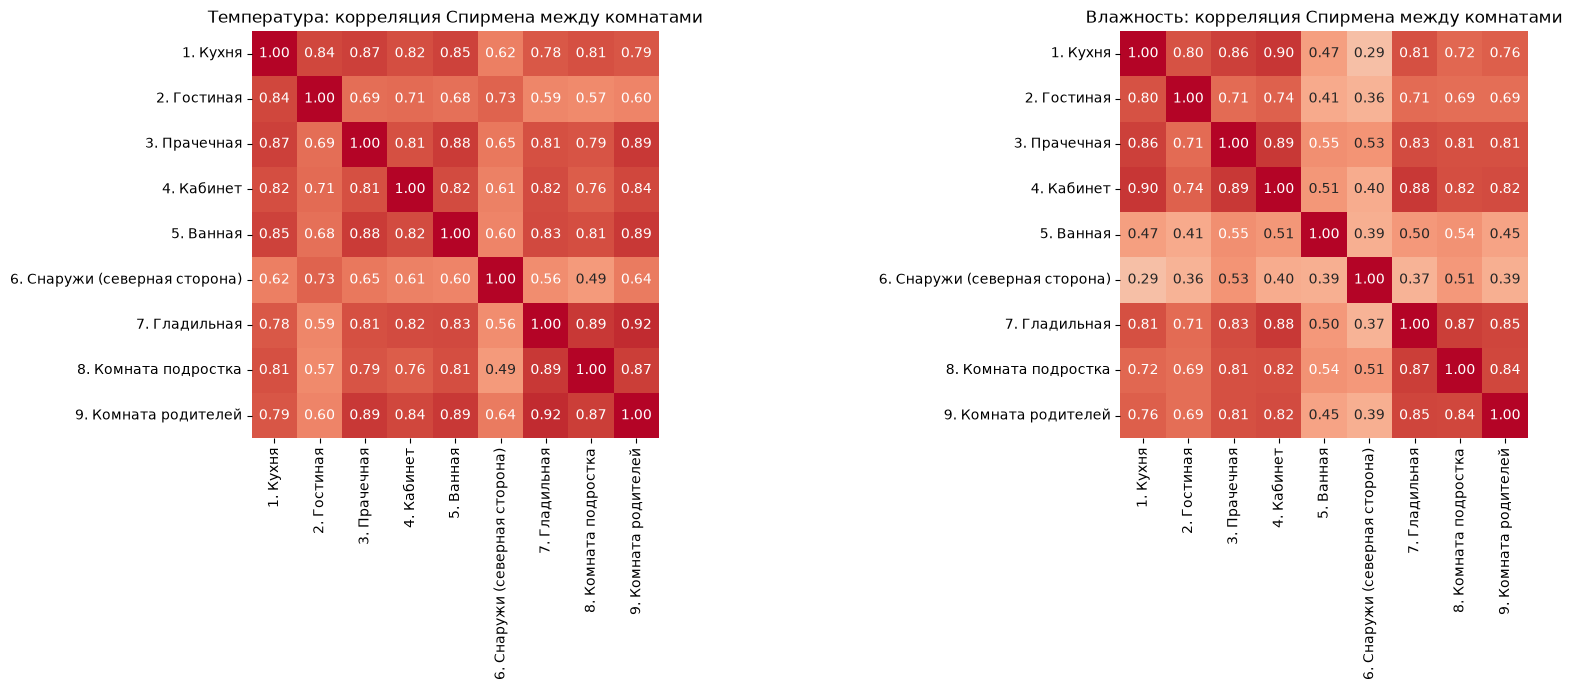

In [8]:
# Корреляция Спирмена между комнатами: отдельно для температуры и для влажности
t_cols = [f'T{i}' for i in rooms]
rh_cols = [f'RH_{i}' for i in rooms]
labels = [f'{i}. {room}' for i, room in rooms.items()]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, cols, title in zip(axes, [t_cols, rh_cols], ['Температура', 'Влажность']):
    corr = df[cols].corr(method='spearman')
    corr.index = corr.columns = labels
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, cbar=False, ax=ax)
    ax.set_title(f'{title}: корреляция Спирмена между комнатами')
plt.tight_layout()
plt.show()

##### Дневные медианы: общий ход во времени

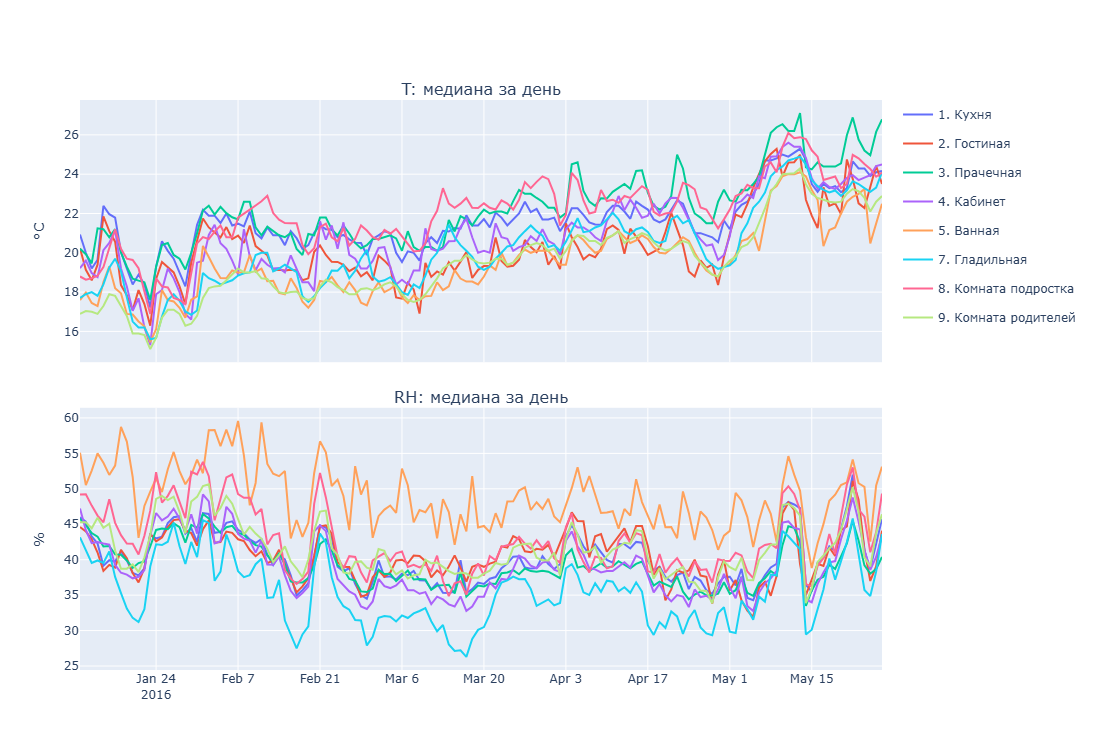

In [9]:
colors = px.colors.qualitative.Plotly   # нужно, чтобы в обоих графиках на одинаковые комнаты был одинаковый цвет
day = df['date'].dt.floor('D')  # метка дня (время округляется до 00:00) — для группировки по дням

fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08, subplot_titles=['T: медиана за день', 'RH: медиана за день'])
for row, prefix, unit in [(1, 'T', '°C'), (2, 'RH_', '%')]:
    daily = df.groupby(day)[[f'{prefix}{i}' for i in indoor]].median()
    for k, (i, room) in enumerate(indoor.items()):
        fig.add_trace(go.Scatter(x=daily.index, y=daily[f'{prefix}{i}'], mode='lines',
                                 name=f'{i}. {room}', legendgroup=room, showlegend=(row == 1),
                                 line=dict(color=colors[k])),
                      row=row, col=1)
    fig.update_yaxes(title_text=unit, row=row, col=1)

fig.update_layout(height=750)
fig.show()

#### Выводы: дневные медианы по комнатам

**Температура**
- **Общая динамика у всех комнат одна**: дом в целом следует за погодой (корреляция средней температуры по дому с уличной `T_out` по дням — 0.76). Общие провалы видны во всех комнатах сразу: 22–23 января (самые холодные дни, до 15–16 °C) и в начале мая.
- **Весной во всех комнатах стало теплее** — рост постепенный: январь 17–20 °C → апрель 20–23 °C → май 22.5–25 °C, всего около +4–5 °C за период.
- **Разница между комнатами стабильная**: между самой тёплой и самой холодной комнатой 3–3.5 °C во все месяцы — комнаты сдвигаются вместе. При этом 3 °C между комнатами сравнимо с сезонным ростом за весь период, то есть комната важна не меньше месяца.
- **Самые тёплые — прачечная и комната подростка**:
  - комната подростка теплее «типичной» комнаты в 91% дней;
  - прачечная с середины марта становится самой тёплой: до 15.03 она на первом месте в 38% дней, после — в 58%; разница с кухней растёт с 0.05 °C в январе до 1.1 °C в мае. Возможная причина — тепло от сушильной машины или солнечная сторона (влажность в прачечной весной при этом снизилась, так что дело вряд ли в сушке белья в комнате) — по этим данным не проверить.
- **Самые холодные — ванная** (самая холодная в 41% дней), **комната родителей** (29%) и **гостиная** (22%). Ванная и комната родителей — самая близкая пара по температуре (типичная разница 0.3 °C).
- **Гостиная весной отстаёт от остальных**: в январе на 0.5 °C теплее среднего по дому, в марте–апреле на 1.2–1.3 °C холоднее. Вместе с тем, что внутри дня T2 ходит вместе с уличной температурой, это говорит о том, что гостиная сильнее всех открыта улице.
- **Кухня и прачечная близки по температуре зимой** (типичная разница 0.6 °C), но весной расходятся из-за прогрева прачечной.

**Влажность**
- **Ожидаемо самая высокая в ванной** (на первом месте в 97% дней) и **самая низкая в гладильной** (на последнем в 90% дней). Вторая по влажности — комната подростка (в январе 47% против 42–43% у большинства комнат).
- **Сезонного тренда нет, но есть колебания**: в марте–апреле в доме суше на 3–5 п.п., чем в январе, в мае снова влажнее.
- **Всплески влажности общие для всех комнат** (около 21 февраля, в середине и в конце мая) — это погода: влажность в доме по дням связана с уличной точкой росы (корреляция 0.61).
- **Ванная — самая «дёрганая»**: типичное изменение медианы от дня ко дню 2.5 п.п. против 0.7–1.5 у остальных комнат (душ бывает не каждый день и не одинаково).
- **Кухня близка по влажности к гостиной и прачечной** (типичная разница 1.2 и 1.0 п.п.).

**Что это значит для модели**
- На уровне дня комнаты во многом дублируют друг друга, поэтому можно использовать среднюю температуру и влажность по дому, а отдельно оставить «особенные» датчики: ванную (RH_5), гостиную (T2), прачечную (T3) и комнату подростка (T8).

##### Корреляция колебаний внутри дня (без сезонного хода)

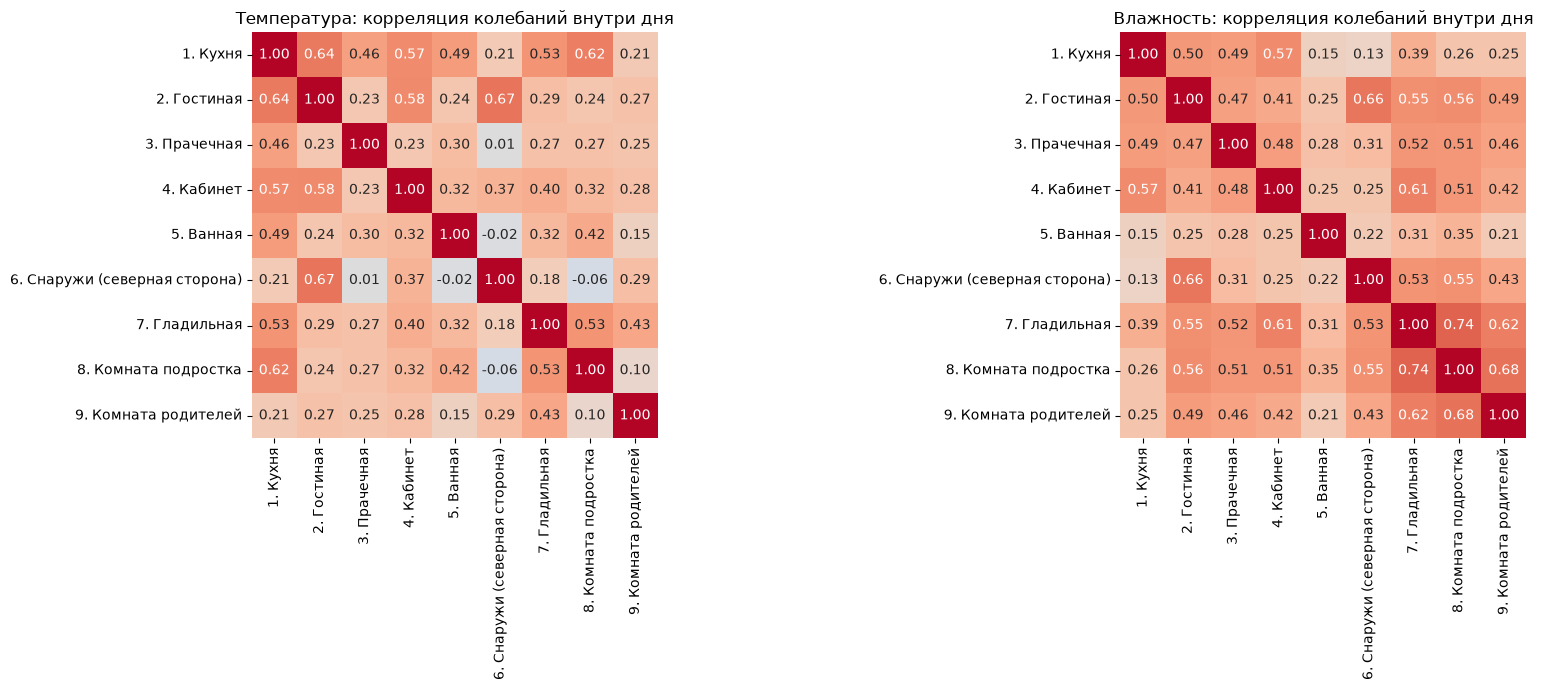

In [10]:
day = df['date'].dt.floor('D')
labels = [f'{i}. {room}' for i, room in rooms.items()]  # все 9 датчиков, включая улицу (6)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, prefix, title in zip(axes, ['T', 'RH_'], ['Температура', 'Влажность']):
    cols = [f'{prefix}{i}' for i in rooms]
    within_day = df[cols] - df.groupby(day)[cols].transform('median')
    corr = within_day.corr(method='spearman')
    corr.index = corr.columns = labels
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, cbar=False, ax=ax)
    ax.set_title(f'{title}: корреляция колебаний внутри дня')
plt.tight_layout()
plt.show()

#### Выводы: корреляция между комнатами

- **Температуры в комнатах очень похожи между собой**: средняя корреляция между внутренними комнатами 0.79, самые близкие пары — гладильная и комната родителей (T7–T9, 0.92), прачечная и комната родителей (T3–T9, 0.89). Дом отапливается как единое целое, и все комнаты вместе следуют за сезоном.
- **Часть этой схожести — общий сезонный тренд**, а не одинаковое поведение комнат: если убрать дневные медианы, корреляции заметно падают (T7–T9: 0.92 → 0.43, T3–T9: 0.89 → 0.25).
- **Влажность похожа слабее** (в среднем 0.72 между комнатами): на неё сильнее влияют локальные события — готовка, душ, стирка.
- После удаления сезонного хода (карта колебаний внутри дня) остаются **реальные сходства**: кухня–гостиная (T 0.64), кухня–комната подростка (T 0.62), гладильная–комната подростка–комната родителей по влажности (0.74 и 0.68), вероятно, соседние комнаты. Ванная по влажности почти ни с кем не связана (0.15–0.35). Прачечная по влажности связана с улицей за весь период (0.53), но не внутри дня (0.31): уличная сырость влияет на неё медленно, а за день — стирка и сушка.
- **Самые «особенные» датчики**:
  - RH_5 (ванная, 0.48) — резкие скачки влажности от душа, не связанные с остальным домом;
  - датчик 6 (улица, 0.61 и 0.40) — ожидаемо отличается от комнат.
  - T2 (гостиная, средняя корреляция с комнатами 0.68) — единственная комната, которая внутри дня ходит вместе с улицей (T2–T6 = 0.67, RH_2–RH_6 = 0.66 на карте колебаний внутри дня). Теплее всего в ней в 14 ч, как на улице (15 ч), а не вечером, как в большинстве комнат; её дневной размах растёт вместе с уличным (0.63). Вероятно, большие окна на солнечную сторону.
- **Что это значит для модели**: температуры в комнатах во многом дублируют друг друга (мультиколлинеарность). Для линейных моделей стоит оставить часть из них или заменить средней температурой по дому; уникальные датчики (T2, RH_5) терять не стоит.

##### Связь признаков с целевой переменной

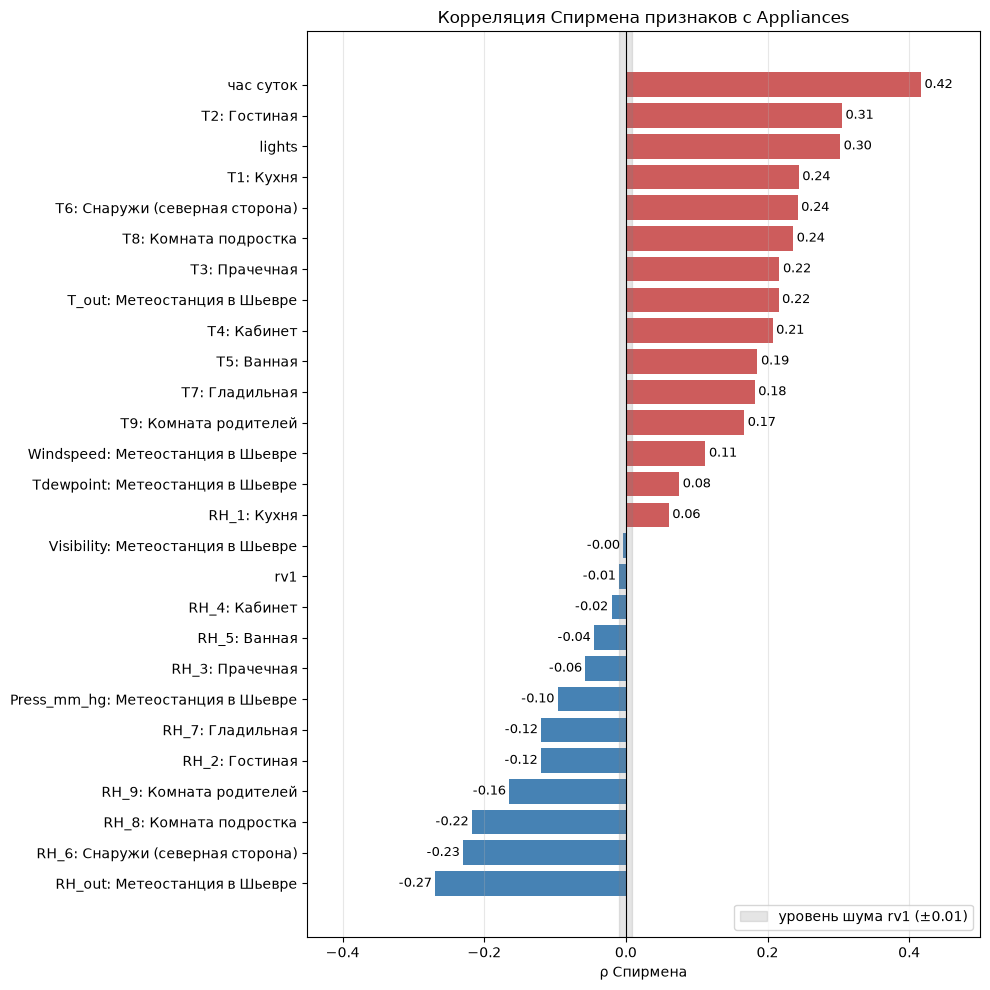

In [11]:
# Корреляция (Спирмен) каждого признака с целевой переменной Appliances
num = df.select_dtypes('number').drop(columns='Appliances')
num['час суток'] = df['date'].dt.hour  # для сравнения: важный, но немонотонный признак
target_corr = num.corrwith(df['Appliances'], method='spearman').sort_values()

places = info['Location'].reindex(target_corr.index)
labels = [f'{col}: {place}' if place not in ('—', 'Дом') and pd.notna(place) else col
          for col, place in zip(target_corr.index, places)]
noise = abs(target_corr['rv1'])

fig, ax = plt.subplots(figsize=(10, 10))
colors = ['indianred' if v > 0 else 'steelblue' for v in target_corr]
ax.barh(labels, target_corr, color=colors)
ax.axvspan(-noise, noise, color='grey', alpha=0.2, label=f'уровень шума rv1 (±{noise:.2f})')
for y, v in enumerate(target_corr):
    ax.text(v + (0.005 if v >= 0 else -0.005), y, f'{v:.2f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Корреляция Спирмена признаков с Appliances')
ax.set_xlabel('ρ Спирмена')
ax.set_xlim(-0.45, 0.5)
ax.grid(axis='x', alpha=0.3)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

#### Выводы: связь признаков с Appliances

- **Сильнее всего с потреблением связан час суток** (ρ = 0.42): потребление определяется распорядком жильцов — ночью медиана 50 Wh, в вечерний пик 17–20 ч до 120 Wh. Связь имеет форму «горки», поэтому монотонный Спирмен её даже занижает.
- **Следом идут T2 (гостиная, 0.31) и lights (0.30)** — оба во многом отражают тот же распорядок: люди дома и не спят → горит свет, работает техника, нагревается гостиная.
- **Все температуры связаны положительно** (0.17–0.31), **почти все влажности — отрицательно** (до −0.27 у RH_out). Вероятное объяснение — суточный цикл: ночью относительная влажность выше, а потребление ниже. Исключение — RH_1 (кухня, +0.06): готовка одновременно повышает влажность и потребление.
- **Около нуля, на уровне случайного rv1** (|ρ| ≤ 0.02): Visibility, RH_4. Поодиночке они с потреблением монотонно не связаны.
- **Все связи слабые или умеренные** (|ρ| < 0.45): ни один признак сам по себе потребление не объясняет. Модели нужно комбинировать признаки, а главный из них — время суток, которого в исходных столбцах нет и который нужно добавить.
- **Оговорка**: корреляция — это совместное изменение, а не причина, и она видит только монотонные связи. Окончательный отбор признаков стоит делать по качеству модели.

##### Распределения по комнатам

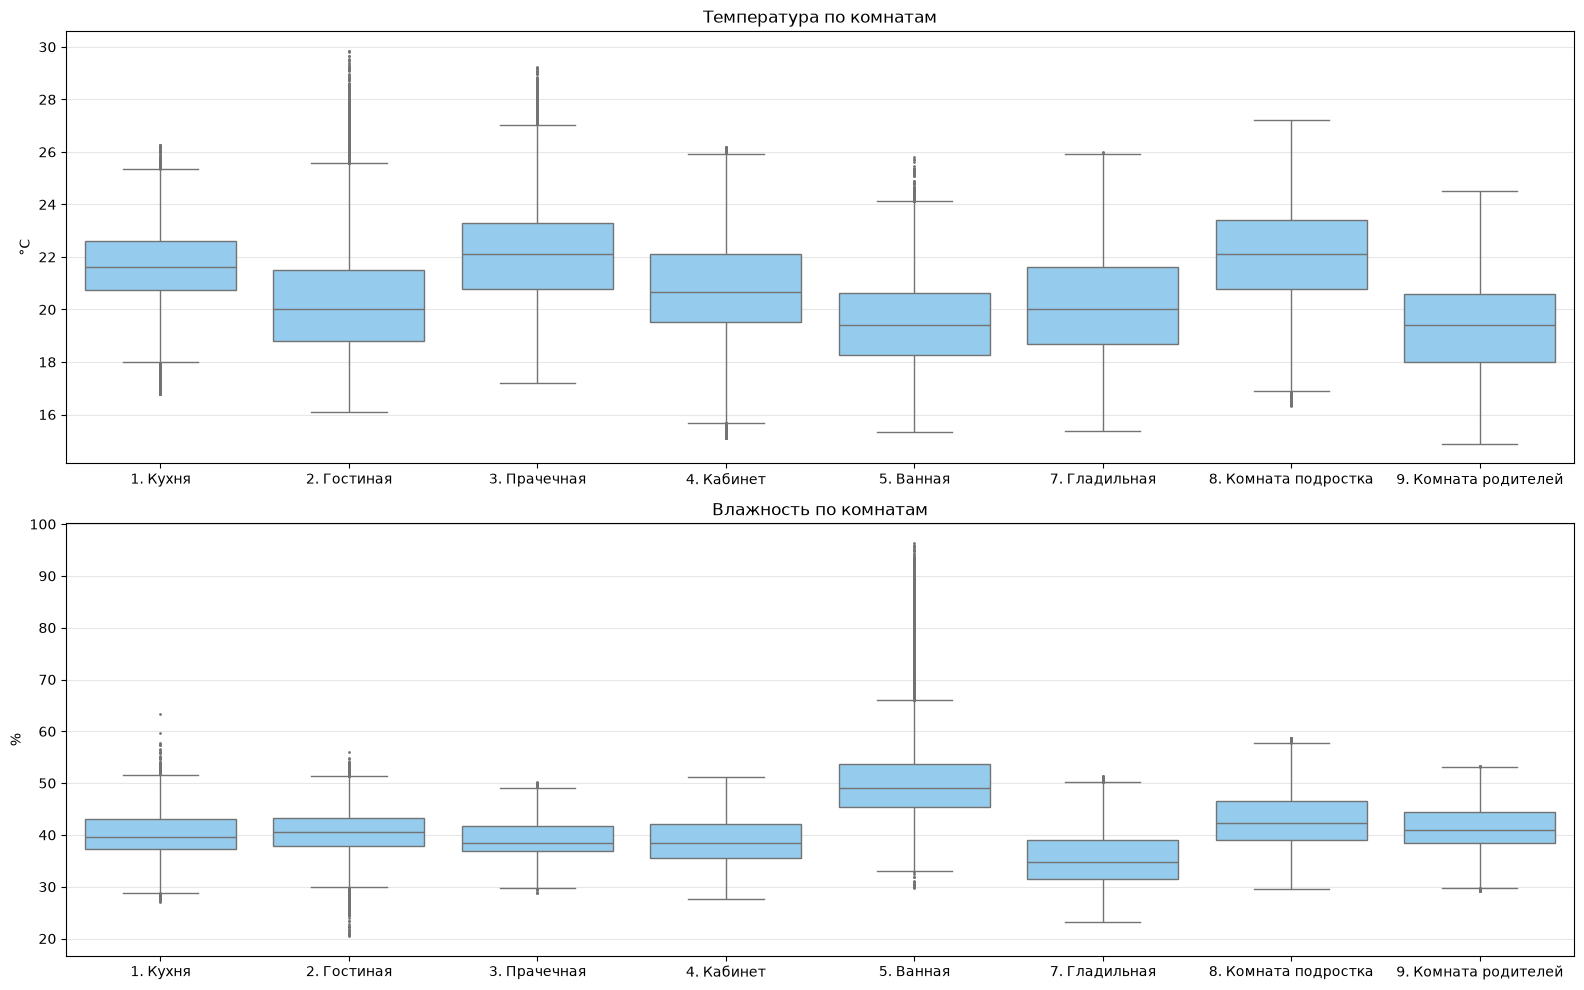

In [12]:
# Распределения по комнатам: переводим данные в «длинный» формат (одна строка = одно измерение)
# Датчик 6 стоит на улице: его разброс намного больше и сжал бы масштаб, поэтому здесь только комнаты
indoor = {i: room for i, room in rooms.items() if i != 6}

fig, axes = plt.subplots(2, 1, figsize=(16, 10))
for ax, prefix, unit in zip(axes, ['T', 'RH_'], ['°C', '%']):
    cols = [f'{prefix}{i}' for i in indoor]
    long = df[cols].melt(var_name='датчик', value_name='значение')
    long['комната'] = long['датчик'].map({f'{prefix}{i}': f'{i}. {room}' for i, room in indoor.items()})
    sns.boxplot(data=long, x='комната', y='значение', color='lightskyblue', fliersize=1, ax=ax)
    ax.set_title(f'{"Температура" if prefix == "T" else "Влажность"} по комнатам')
    ax.set_xlabel('')
    ax.set_ylabel(unit)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#### Выводы: выбросы и медианы

- по температуре: самые тёплые: **прачечная** и **комната подростка**, самые холодные — **ванная** и **комната родителей**
- по температуре: **кухня** самая стабильная (равные усы и медиана ровно между квартилями), а у **гостиной** самая большая ассиметрия
- по влажности **ванная** выделяется всем сразу: самая высокая медиана, самый широкий ящик и длинный хвост выбросов вверх
- по влажности: **гладильная** самая сухая, остальные комнаты близки друг к другу
- в целом каких-то **подозрительных выбросов нет**: у кухни есть всплески по влажности, вероятно, связанные с готовкой (например, кипящей водой), гостиная нагревается от солнца, в ванной работает душ
- распределения по температуре во всех комнатах **симметричные и спокойные**

##### Суточные профили по комнатам

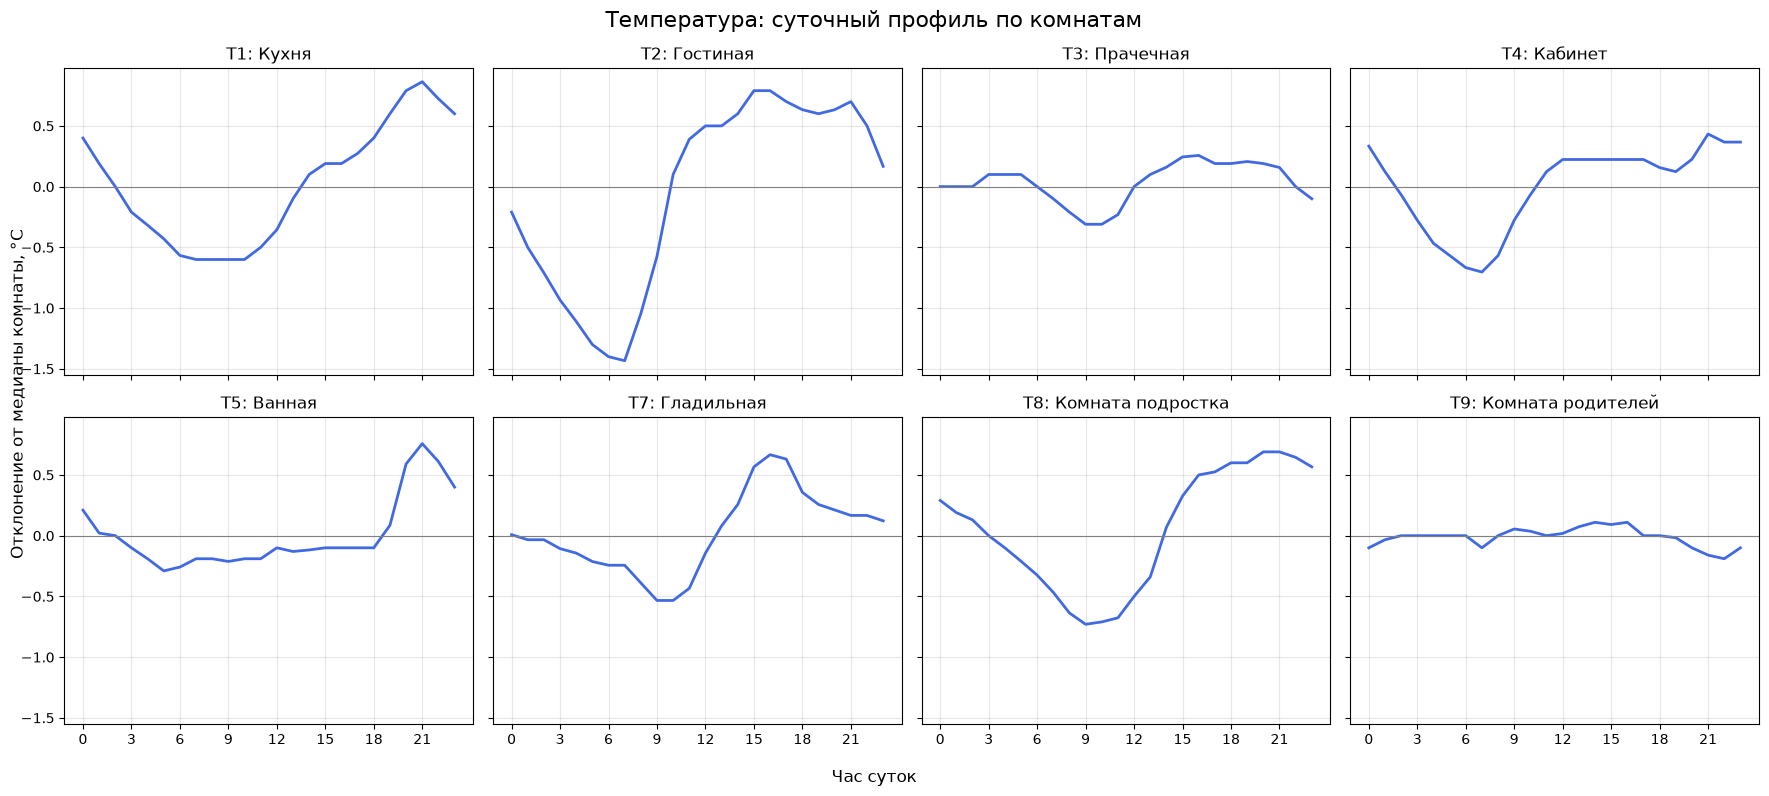

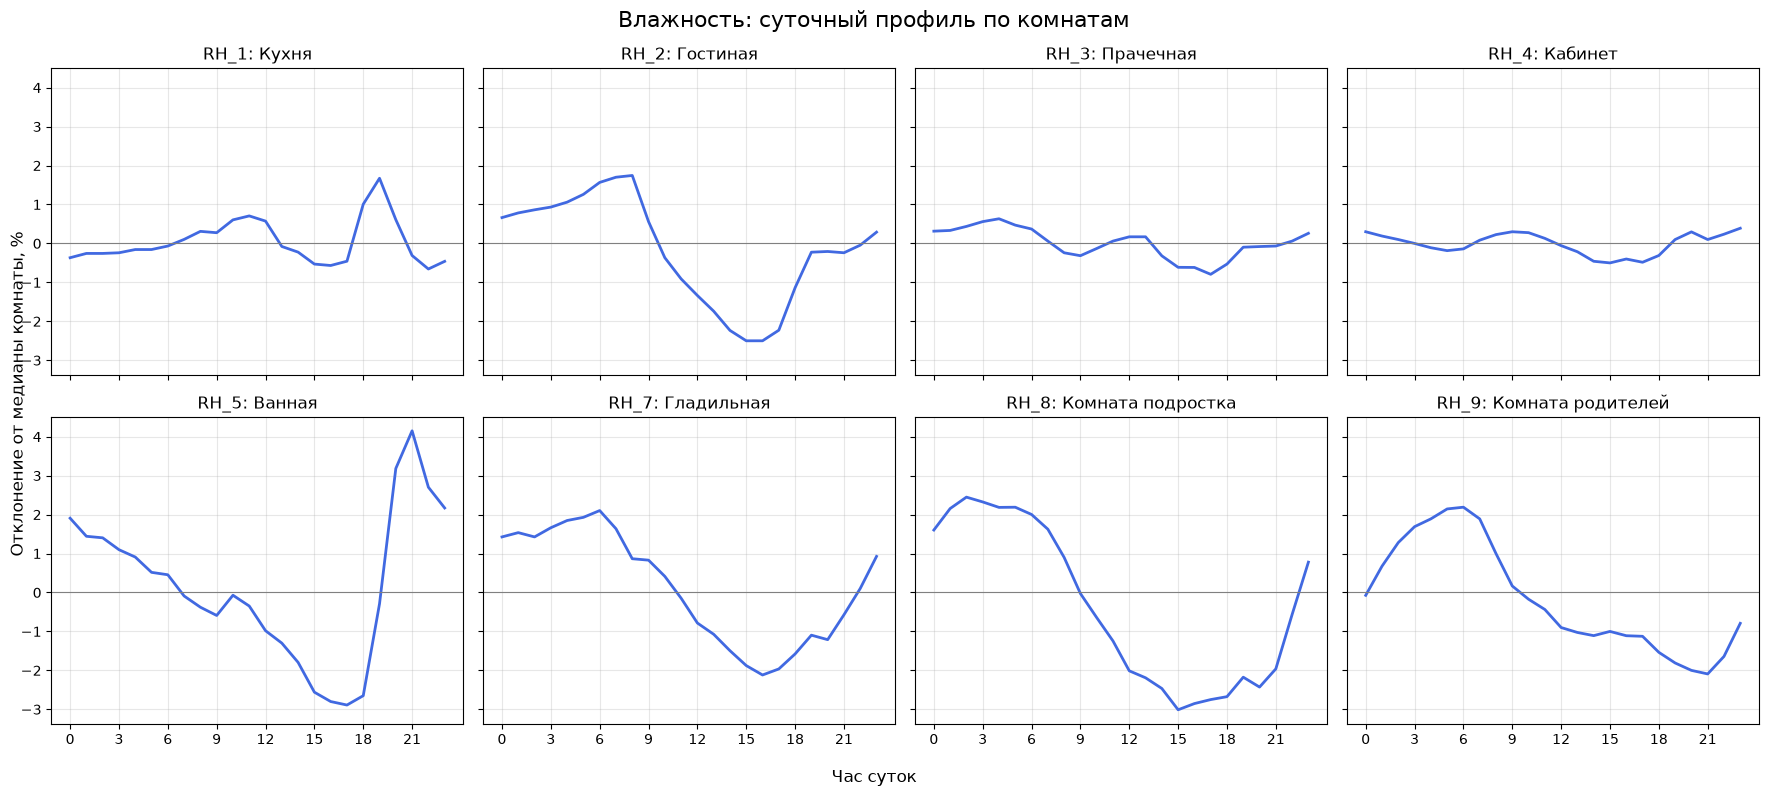

,комната,суточный размах,час максимума,резкие скачки за 10 мин (99%)
датчик,,,,
T1,Кухня,1.46,21,0.14
RH_1,Кухня,2.33,19,2.13
T2,Гостиная,2.22,15,0.41
RH_2,Гостиная,4.24,8,1.11
T3,Прачечная,0.57,16,0.28
RH_3,Прачечная,1.43,4,0.86
T4,Кабинет,1.14,21,0.40
RH_4,Кабинет,0.89,23,0.66
T5,Ванная,1.05,21,0.54


In [13]:
hour = df['date'].dt.hour

for prefix, title, unit in [('T', 'Температура', '°C'), ('RH_', 'Влажность', '%')]:
    fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
    for ax, (i, room) in zip(axes.flatten(), indoor.items()):  # улицу исключаем, т.к. её отклонения природны и для данного сравнения не релевантны
        col = f'{prefix}{i}'
        profile = df[col].groupby(hour).median()  # группировка по одинаковому часу по всему датасету
        ax.plot(profile.index, profile - df[col].median(), color='royalblue', linewidth=2)
        ax.axhline(0, color='grey', linewidth=0.8)
        ax.set_title(f'{col}: {room}')
        ax.set_xticks(range(0, 24, 3))
        ax.grid(alpha=0.3)
    fig.supxlabel('Час суток')
    fig.supylabel(f'Отклонение от медианы комнаты, {unit}')
    fig.suptitle(f'{title}: суточный профиль по комнатам', fontsize=16)
    plt.tight_layout()
    plt.show()

rows = []
for i, room in indoor.items():
    for col in (f'T{i}', f'RH_{i}'):
        profile = df[col].groupby(hour).median()
        rows.append({'датчик': col, 'комната': room,
                     'суточный размах': round(profile.max() - profile.min(), 2),
                     'час максимума': profile.idxmax(),
                     'резкие скачки за 10 мин (99%)': round(df[col].diff().abs().quantile(0.99), 2)})
pd.DataFrame(rows).set_index('датчик')

#### Выводы: суточные профили по комнатам

- самый большой суточный размах от медианы по температуре у гостиной (2.2 °C), по влажности у ванной (7%)
- кухня, кабинет, ванная и комната подростка теплее всего вечером (20–21ч), гостиная и гладильная — днём (15–16ч); комната родителей и прачечная почти не меняются в течение суток
- динамика влажности похожая в гостиной, кладильной и комнатах подростка и родителей, что связано с природными причинами: на улице теплее, влажность ниже
- влажность в прачечной и кабинете не отклоняется от медианы в течение дня
- влажность в кухне имеет два пика: утренний небольшой между 10 и 12 часами и вечерный заметный между 18 и 19 часами
- датчики, которые реагируют на активности людей, потенциально могут быть полезнее для модели: RH_5 (душ), RH_1 (готовка), T5 (вечер в ванной)
- плоские датчики (T9, T3, RH_4) про время суток почти ничего не говорят. Если они и полезны, то как сезонный фон

#### Целевая переменная Appliances

##### Распределение

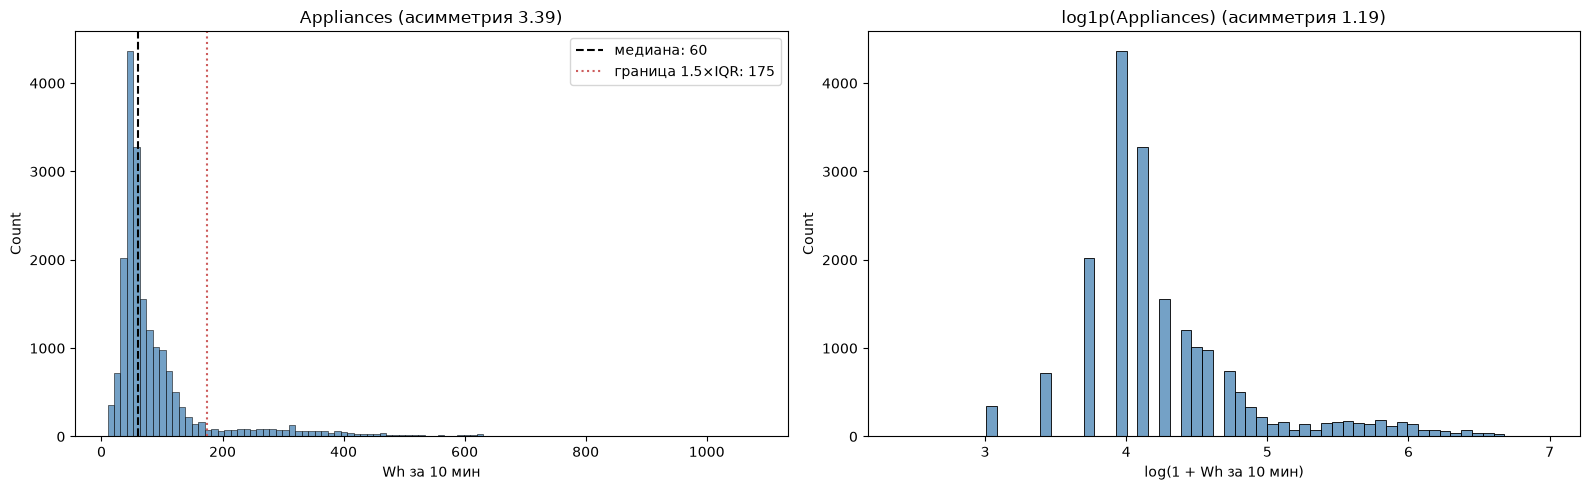

count    19735.0
mean        97.7
std        102.5
min         10.0
25%         50.0
50%         60.0
75%        100.0
90%        196.0
99%        576.6
max       1080.0

Выше границы 175: 10.8% записей
Самые частые значения: {50: 4368, 60: 3282, 40: 2019, 70: 1560, 80: 1205}


In [14]:
app = df['Appliances']
q1, q3 = app.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)   # граница выбросов (1.5×IQR)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(app, bins=100, color='steelblue', ax=axes[0])
axes[0].axvline(app.median(), color='black', linestyle='--', label=f'медиана: {app.median():.0f}')
axes[0].axvline(upper, color='indianred', linestyle=':', label=f'граница 1.5×IQR: {upper:.0f}')
axes[0].set_title(f'Appliances (асимметрия {app.skew():.2f})')
axes[0].set_xlabel('Wh за 10 мин')
axes[0].legend()

sns.histplot(np.log1p(app), bins=60, color='steelblue', ax=axes[1])
axes[1].set_title(f'log1p(Appliances) (асимметрия {np.log1p(app).skew():.2f})')
axes[1].set_xlabel('log(1 + Wh за 10 мин)')
plt.tight_layout()
plt.show()

print(app.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1).to_string(), end='\n\n')
print(f'Выше границы {upper:.0f}: {(app > upper).mean():.1%} записей')
print('Самые частые значения:', app.value_counts().head(5).to_dict())

**Выводы: распределение Appliances**

- **Сильная правосторонняя асимметрия (3.39):** типичное потребление 50–100 Wh за 10 мин (медиана 60, чаще всего 50 и 60 — фоновая нагрузка), но есть длинный хвост редких пиков до 1080.
- **Среднее (97.7) заметно выше медианы** — его тянут вверх пики, поэтому «типичное» потребление описывает медиана.
- **Выше границы 1.5×IQR (175) — 10.8% записей.** Для ошибок это слишком много: это обычный режим высокой нагрузки (готовка, стирка и т.п.), поэтому удалять эти значения не нужно — именно их модель и должна научиться предсказывать.
- **После `log1p` асимметрия падает до 1.19** — распределение близко к симметричному. Это кандидат на преобразование цели (особенно для линейных моделей): обучаемся на `log1p(Appliances)`, прогноз возвращаем через `expm1`, метрики считаем в Wh.
- **Метрика:** MAE устойчивее к пикам, чем MSE/RMSE; RMSE стоит смотреть дополнительно, если важно, насколько хорошо модель ловит пики.

##### Потребление по времени

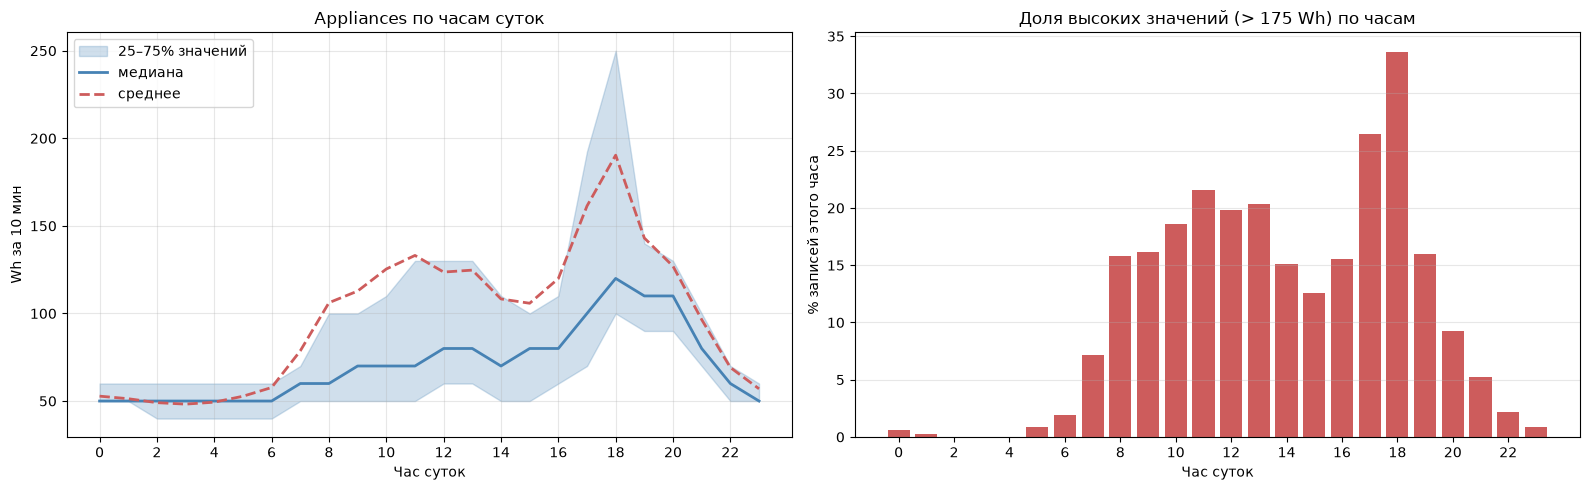

In [15]:
hour = df['date'].dt.hour
by_hour = app.groupby(hour).quantile([0.25, 0.5, 0.75]).unstack()  # считаем квартили для каждого часа -> в удобном формате, а не все 72 за сутки
share_high = (app > upper).groupby(hour).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax = axes[0]
ax.fill_between(by_hour.index, by_hour[0.25], by_hour[0.75], color='steelblue', alpha=0.25, label='25–75% значений')
ax.plot(by_hour.index, by_hour[0.5], color='steelblue', linewidth=2, label='медиана')
ax.plot(by_hour.index, app.groupby(hour).mean(), color='indianred', linewidth=2, linestyle='--', label='среднее')
ax.set(title='Appliances по часам суток', xlabel='Час суток', ylabel='Wh за 10 мин', xticks=range(0, 24, 2))
ax.grid(alpha=0.3)
ax.legend()

ax = axes[1]
ax.bar(share_high.index, share_high, color='indianred')
ax.set(title=f'Доля высоких значений (> {upper:.0f} Wh) по часам', xlabel='Час суток', ylabel='% записей этого часа', xticks=range(0, 24, 2))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Выводы: Appliances по часам суток**

- **Ночь (0–6 ч) — фоновое потребление:** медиана 50 Wh за 10 мин, коридор 40–60, высоких значений почти нет (0–2%). Работает только то, что включено всегда (холодильник, техника в режиме ожидания).
- **Утро и день (7–16 ч) — умеренное потребление с частыми пиками:** медиана 60–80, но доля высоких значений уже 15–21%, а среднее (106–133) заметно выше медианы — днём бывают отдельные короткие включения мощной техники.
- **Вечерний пик (17–20 ч):** медиана 100–120, максимальная доля высоких значений в 18 ч — 34%, верхняя граница коридора доходит до 250. В 19–20 ч медиана остаётся высокой (110), но пиков меньше (9–16%) — потребление стабильно высокое.
- **После 21 ч — спад** к ночному фону.
- **Среднее во все часы выше медианы**, сильнее всего днём и вечером: его тянут вверх редкие пики. Поэтому типичное потребление описывает медиана, а среднее показывает, сколько энергии уходит на пики.
- **Для модели и метрик:** ошибка будет сильно зависеть от времени суток — ночью потребление почти постоянное и предсказывается легко, а днём и вечером из-за пиков ошибки будут больше. Модель, минимизирующая MSE, будет тянуться к среднему (к пикам), а MAE — к медиане; это стоит учитывать при выборе метрики. Час суток — обязательный признак.

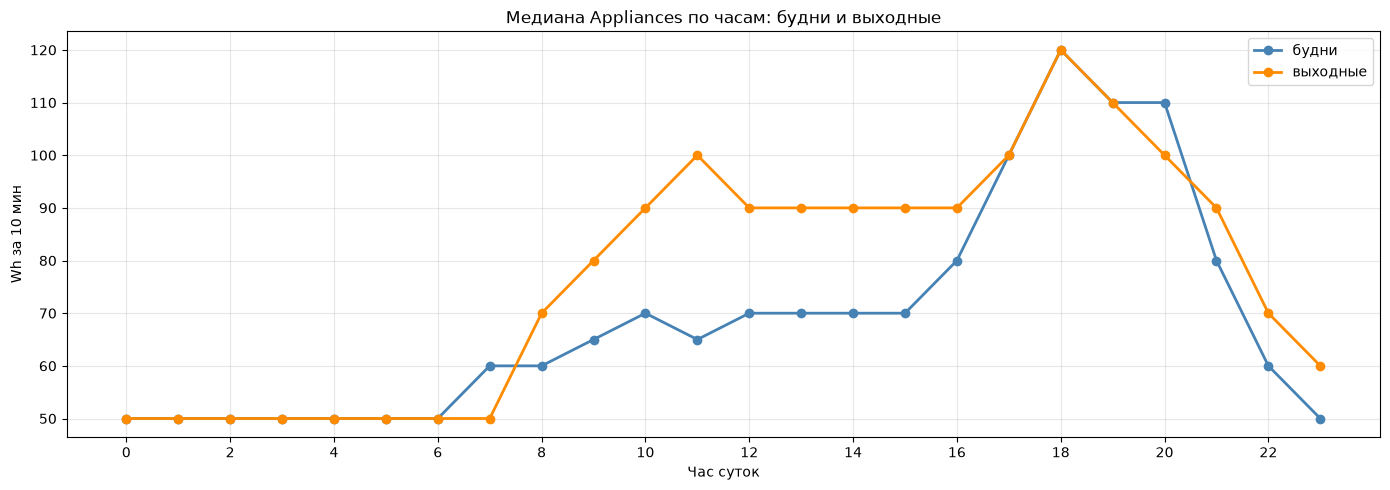

,дней в данных,медиана,среднее,"доля > 175, %"
Пн,20,60.0,111.5,15.2
Вт,20,60.0,87.1,7.9
Ср,20,70.0,89.9,8.0
Чт,20,60.0,90.4,8.6
Пт,20,60.0,104.6,14.6
Сб,19,70.0,106.2,12.9
Вс,19,60.0,94.9,8.9


In [16]:
# Будни и выходные: медиана Appliances по часам
weekday = df['date'].dt.dayofweek
is_weekend = weekday >= 5
by_daytype = app.groupby([hour, is_weekend]).median().unstack()
by_daytype.columns = ['будни', 'выходные']

fig, ax = plt.subplots(figsize=(14, 5))
by_daytype.plot(ax=ax, marker='o', linewidth=2, color=['steelblue', 'darkorange'])
ax.set(title='Медиана Appliances по часам: будни и выходные', xlabel='Час суток', ylabel='Wh за 10 мин', xticks=range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Сводка по дням недели
days_ru = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
by_weekday = pd.DataFrame({
    'дней в данных': df['date'].dt.floor('D').groupby(weekday).nunique(),
    'медиана': app.groupby(weekday).median(),
    'среднее': app.groupby(weekday).mean().round(1),
    f'доля > {upper:.0f}, %': ((app > upper).groupby(weekday).mean() * 100).round(1),
})
by_weekday.index = days_ru
by_weekday

**Выводы: будни и выходные**

- **Выходные отличаются от будней только тогда, когда люди дома вместо работы или учёбы:** с 9 до 16 ч медиана в выходные 80–100 против 65–80 в будни (в среднем 90 против 70).
- **В выходные утро начинается позже, а вечер заканчивается позже:** в 7 ч в выходные ещё ночной фон (50, в будни уже 60), а в 21–23 ч потребление на 10 Wh выше, чем в будни, — по выходным дольше спят и позже ложатся.
- **Ночь и вечерний пик от типа дня не зависят:** 0–6 ч и 17–20 ч линии совпадают.
- **По дням недели медианы за сутки почти одинаковые (60–70), но пиков больше в понедельник (15.2% записей выше 175), пятницу (14.6%) и субботу (12.9%)**, чем во вторник–четверг (8–9%). Понедельник и пятница по числу пиков ближе к выходным — возможно, это дни стирки, уборки или работы из дома; по этим данным причину не установить. На каждый день недели всего 19–20 дней, так что эти различия стоит считать предварительными.
- **Для модели:** флаг «выходной» полезен только вместе с часом суток (он меняет дневные и поздние вечерние часы), сам по себе он мало что даёт; отдельный признак «день недели» вряд ли нужен.

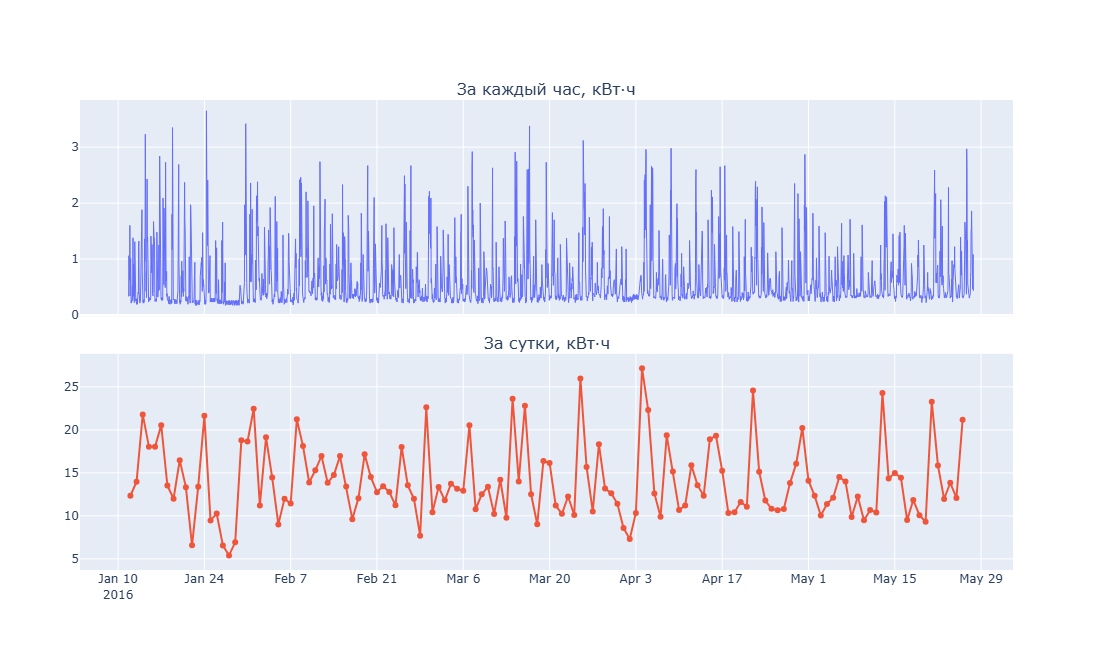

In [17]:
# Весь ряд: потребление за каждый час и за сутки (Wh → кВт·ч)
hourly_kwh = app.groupby(df['date'].dt.floor('h')).sum() / 1000
daily_kwh = (app.groupby(df['date'].dt.floor('D')).sum() / 1000).iloc[1:-1]

fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                    subplot_titles=['За каждый час, кВт·ч', 'За сутки, кВт·ч'])
fig.add_trace(go.Scatter(x=hourly_kwh.index, y=hourly_kwh, mode='lines', name='за час', line=dict(width=1)), row=1, col=1)
fig.add_trace(go.Scatter(x=daily_kwh.index, y=daily_kwh, mode='lines+markers', name='за сутки'), row=2, col=1)
fig.update_layout(height=650, showlegend=False)
fig.show()

**Выводы: весь ряд потребления**

- **За сутки дом тратит в среднем 14 кВт·ч** (медиана 13.3, обычно 11–16), но разброс между днями большой: от 5.4 до 27.2 кВт·ч (коэффициент вариации 0.31).
- **Устойчивого тренда за период нет:** скользящее среднее за неделю в начале 16.9 кВт·ч/сутки, в конце 15.4 — потребление не растёт и не падает вместе с сезоном. Суточное потребление почти не связано со средней уличной температурой дня (ρ = −0.09).
- **Самые «тихие» дни — конец января** (22, 27, 28.01: 5.4–6.6 кВт·ч), возможно, жильцов не было дома; **самые «тяжёлые» — конец марта и апрель** (25.03, 04.04, 22.04: 24.6–27.2 кВт·ч).
- **По часовому графику видно, что ряд состоит из низкого фона и частых коротких пиков** (за час обычно 0.3–0.7 кВт·ч, пики до 3.65) — потребление определяется отдельными включениями техники, а не плавными изменениями.
- **Явных сбоев или «странных» периодов** (долгих нулей, ступенек, пропавших кусков) не видно — ряд можно использовать целиком.

In [18]:
# Сравнение месяцев только по относительным показателям (январь и май неполные)
month = df['date'].dt.month
by_month = pd.DataFrame({
    'дней в данных': df['date'].dt.floor('D').groupby(month).nunique(),
    'медиана': app.groupby(month).median(),
    'среднее': app.groupby(month).mean().round(1),
    f'доля > {upper:.0f}, %': ((app > upper).groupby(month).mean() * 100).round(1),
    'кВт·ч в сутки (в среднем)': (app.groupby(month).mean() * 144 / 1000).round(1),  # 144 записи в сутках
})
by_month.index = ['январь', 'февраль', 'март', 'апрель', 'май']
by_month

,дней в данных,медиана,среднее,"доля > 175, %",кВт·ч в сутки (в среднем)
январь,21,50.0,97.0,12.7,14.0
февраль,29,60.0,100.9,12.6,14.5
март,31,60.0,97.0,10.3,14.0
апрель,30,60.0,98.9,10.4,14.2
май,27,60.0,94.2,8.5,13.6


**Выводы: сравнение месяцев**

- **Месяцы почти не отличаются:** медиана 50–60, среднее 94–101 Wh за 10 мин, в сутки 13.6–14.5 кВт·ч во все месяцы.
- **Единственная заметная разница — доля пиков:** она постепенно снижается с 12.7% в январе–феврале до 8.5% в мае.
- **Вывод:** сезон (зима → весна) почти не влияет на потребление бытовой техники, в отличие от температуры в комнатах. Признак «месяц» для модели, скорее всего, бесполезен, а с делением по времени ещё и опасен: месяцы из test не встретятся в train.

#### Освещение lights

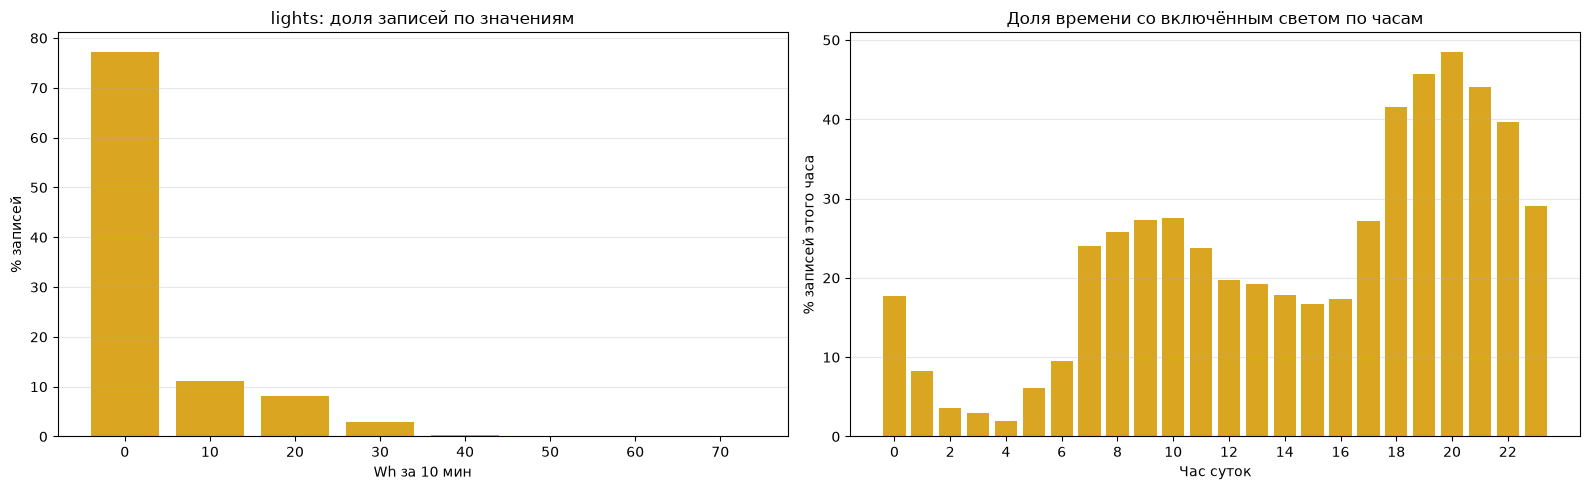

lights
0     77.3
10    11.2
20     8.2
30     2.8
40     0.4
50     0.0
60     0.0
70     0.0


In [19]:
# lights: какие значения встречаются и когда горит свет
lights = df['lights']
light_on = lights > 0
light_counts = lights.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(light_counts.index.astype(str), light_counts / len(df) * 100, color='goldenrod')
axes[0].set(title='lights: доля записей по значениям', xlabel='Wh за 10 мин', ylabel='% записей')

on_by_hour = light_on.groupby(hour).mean() * 100
axes[1].bar(on_by_hour.index, on_by_hour, color='goldenrod')
axes[1].set(title='Доля времени со включённым светом по часам', xlabel='Час суток',
            ylabel='% записей этого часа', xticks=range(0, 24, 2))
for ax in axes:
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print((light_counts / len(df) * 100).round(1).to_string())

**Выводы: значения lights и когда горит свет**

- **`lights` — не бинарный признак, но почти:** 77.3% записей — 0 (свет выключен), 11.2% — 10, 8.2% — 20, 2.8% — 30, выше 40 практически не бывает. Свет горит в 22.7% записей и даёт всего ~4% от суммарного потребления (свет + техника).
- **Свет включают утром (7–11 ч, ~25% записей) и особенно вечером (18–22 ч, 40–49%)**, ночью почти никогда.
- **Чем длиннее день, тем реже горит свет:** доля записей со светом в феврале 35%, в мае 11% — `lights` отчасти отражает длину светового дня.
- **Для модели** `lights` удобно использовать как флаг «свет включён» (`lights > 0`): различия между 10, 20 и 30 Wh вряд ли несут много информации.

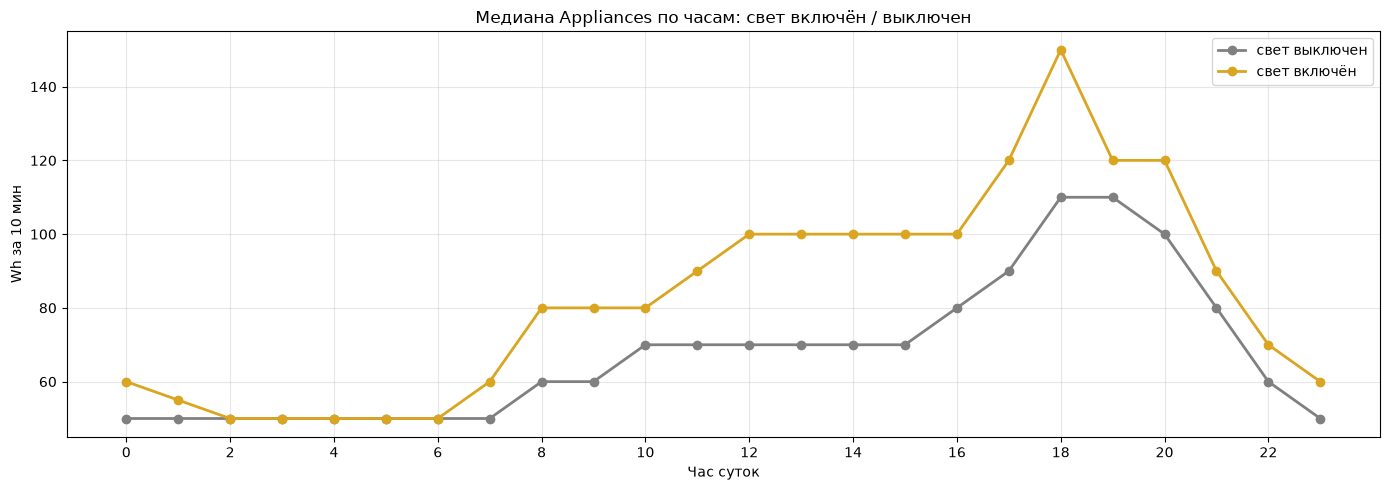

Меньше всего записей со светом в одном часе: 16
Спирмен lights – Appliances: 0.3
То же с поправкой на час суток: 0.2


In [20]:
# Потребление техники при включённом и выключенном свете — отдельно для каждого часа,
# чтобы сравнение не смешивалось со временем суток (свет горит в основном утром и вечером)
by_light = app.groupby([hour, light_on]).median().unstack()
by_light.columns = ['свет выключен', 'свет включён']

fig, ax = plt.subplots(figsize=(14, 5))
by_light.plot(ax=ax, marker='o', linewidth=2, color=['grey', 'goldenrod'])
ax.set(title='Медиана Appliances по часам: свет включён / выключен', xlabel='Час суток',
       ylabel='Wh за 10 мин', xticks=range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

within_hour = lambda s: s - s.groupby(hour).transform('median')   # убираем типичный для часа уровень
print('Меньше всего записей со светом в одном часе:', light_on.groupby(hour).sum().min())
print('Спирмен lights – Appliances:', round(lights.corr(app, method='spearman'), 2))
print('То же с поправкой на час суток:', round(within_hour(lights).corr(within_hour(app), method='spearman'), 2))

**Выводы: потребление техники при включённом и выключенном свете**

- **В одни и те же часы при включённом свете техника потребляет больше:** в дневные и вечерние часы медиана выше на 10–40 Wh за 10 мин (сильнее всего в 18 ч: 150 против 110), ночью (2–6 ч) разницы нет.
- **Связь не только из-за времени суток:** корреляция `lights` с `Appliances` 0.30, с поправкой на час — 0.20. Свет — это признак того, что люди дома и активны, и он добавляет информацию сверх часа суток.
- **Важно — риск утечки:** `lights` измеряется одновременно с `Appliances`. Использовать его как признак можно, только если по постановке задачи на момент прогноза он известен (например, с лагом: свет 10 минут назад). Иначе модель будет «подглядывать» в то же самое событие, которое предсказывает.

#### Погода и цель с поправкой на время суток

Многие признаки связаны с потреблением через время суток: днём теплее, суше и светлее — и днём же люди дома. Чтобы отделить «собственную» связь признака от этого общего ритма, из признака и из `Appliances` вычитаем типичное для каждого часа значение (медиану по часу) и считаем корреляцию заново.

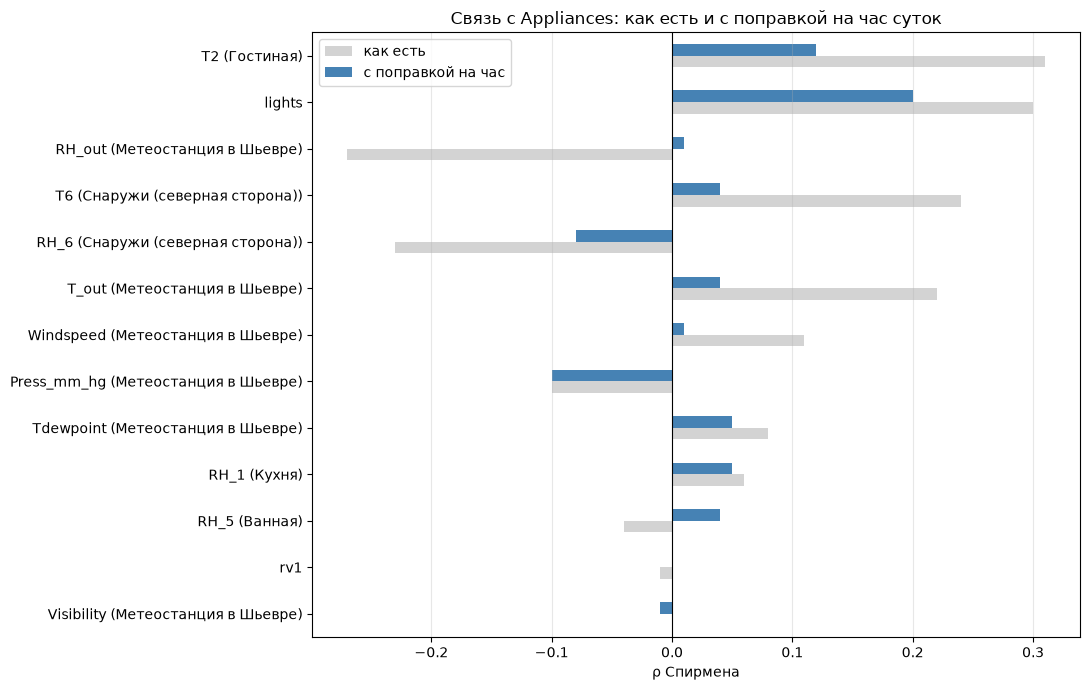

,как есть,с поправкой на час
Visibility (Метеостанция в Шьевре),-0.00,-0.01
rv1,-0.01,-0.00
RH_5 (Ванная),-0.04,0.04
RH_1 (Кухня),0.06,0.05
Tdewpoint (Метеостанция в Шьевре),0.08,0.05
Press_mm_hg (Метеостанция в Шьевре),-0.10,-0.10
Windspeed (Метеостанция в Шьевре),0.11,0.01
T_out (Метеостанция в Шьевре),0.22,0.04
RH_6 (Снаружи (северная сторона)),-0.23,-0.08
T6 (Снаружи (северная сторона)),0.24,0.04


In [21]:
# Спирмен с Appliances: как есть и с поправкой на час суток
check_cols = ['T_out', 'RH_out', 'Tdewpoint', 'Press_mm_hg', 'Windspeed', 'Visibility', 'T6', 'RH_6', 'T2', 'RH_5', 'RH_1', 'lights', 'rv1']
adjusted = pd.DataFrame({
    'как есть': [df[c].corr(app, method='spearman') for c in check_cols],
    'с поправкой на час': [within_hour(df[c]).corr(within_hour(app), method='spearman') for c in check_cols],
}, index=check_cols).round(2)
adjusted = adjusted.loc[adjusted['как есть'].abs().sort_values().index]
adjusted.index = [f'{c} ({info.loc[c, "Location"]})' if info.loc[c, 'Location'] not in ('—', 'Дом') else c for c in adjusted.index]

ax = adjusted.plot.barh(figsize=(11, 7), color=['lightgrey', 'steelblue'])
ax.axvline(0, color='black', linewidth=0.8)
ax.set(title='Связь с Appliances: как есть и с поправкой на час суток', xlabel='ρ Спирмена')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()
adjusted

**Выводы: погода и цель с поправкой на время суток**

- **Связь погоды с потреблением почти полностью объясняется временем суток.** После поправки на час корреляции падают практически до нуля: `T_out` 0.22 → 0.04, `RH_out` −0.27 → 0.01, `T6` 0.24 → 0.04, `Windspeed` 0.11 → 0.01. Днём теплее, суше и ветренее — и днём же люди дома; сама погода на потребление техники почти не влияет.
- **Сохраняют связь:** `lights` (0.30 → 0.20) — признак присутствия людей; `T2` (гостиная, 0.31 → 0.12) — частично; `Press_mm_hg` (−0.10 → −0.10) — давление не имеет суточного цикла, поэтому поправка его не меняет, но связь слабая и может быть совпадением отдельных периодов.
- **Датчики «событий» (RH_5 — душ, RH_1 — готовка) в «уровнях» почти не связаны с потреблением** (|ρ| ≤ 0.06) — если они и полезны, то в виде изменений (рост влажности за последние 10–20 минут), а не текущего значения.
- **Для модели:** погодные признаки сами по себе мало что добавят к часу суток; вероятно, большую часть из них можно не использовать или проверить их вклад на модели. Главные источники информации — время (час, выходной) и признаки присутствия людей.

#### Общие выводы EDA

**Данные**
- 19 735 записей с шагом 10 минут, 11.01.2016 – 27.05.2016 (4.5 месяца, только зима и весна одного года). Пропусков, дублей и сбоев временной сетки нет.
- `rv1` и `rv2` — одна и та же случайная величина; `rv2` удалена, `rv1` оставлена как ориентир «уровня шума».
- `Appliances` и `lights` — энергия в Wh за 10 минут, а не мощность.

**Целевая переменная `Appliances`**
- Сильно скошена вправо (асимметрия 3.39): фон 50–60 Wh, редкие пики до 1080. После `log1p` асимметрия 1.19.
- 10.8% записей выше 1.5×IQR (175) — это обычный режим высокой нагрузки, а не ошибки; удалять их нельзя.
- Потребление определяется распорядком жильцов: ночью фон, днём умеренно с частыми пиками, вечерний пик 17–20 ч каждый день. Выходные отличаются от будней только дневными часами.
- Ни тренда, ни сезонности за период нет: около 14 кВт·ч в сутки во все месяцы.
- Сильная автокорреляция (0.75 через 10 минут) и суточный цикл (0.22 через сутки).

**Признаки**
- Сильнее всего с потреблением связан **час суток** (ρ = 0.42, связь немонотонная — «горка»).
- **Погода** связана с потреблением почти только через время суток; после поправки на час связь пропадает.
- **Температура и влажность в комнатах** сильно связаны между собой (мультиколлинеарность), во многом из-за общего сезонного хода. Особенные датчики: T2 (гостиная, следует за улицей, вероятно, солнечная сторона), RH_5 (ванная, душ), RH_1 (кухня, готовка).
- **`lights`** — признак присутствия людей, сохраняет связь с потреблением и после поправки на час (0.20), но может быть утечкой, если на момент прогноза он неизвестен.

**Что делать на этапе подготовки данных и моделирования**
1. Делить данные **по времени** (train — прошлое, test — будущее), для кросс-валидации — `TimeSeriesSplit`; случайное перемешивание даст утечку.
2. Добавить признаки времени: **час суток** (sin/cos, чтобы 23 и 0 были рядом), **флаг выходного**; признак «месяц» не использовать.
3. Если по постановке задачи прошлое потребление известно — **лаги** (10–30 минут назад, сутки назад) и скользящее среднее; `lights` — только если известен на момент прогноза (или с лагом).
4. Попробовать **`log1p` цели** (особенно для линейных моделей), прогноз возвращать через `expm1`.
5. Против мультиколлинеарности: средние температура и влажность по дому + особенные датчики (T2, RH_5, RH_1, T3, T8); для линейных моделей — **стандартизация** и регуляризация (Ridge/Lasso); модели на деревьях к этому нечувствительны.
6. Признаки событий (душ, готовка) пробовать в виде **изменений** за последние 10–20 минут.
7. Метрика: **MAE** (устойчива к пикам) + RMSE дополнительно; ориентир для моделей — прогноз «как 10 минут назад».
8. Окончательный отбор признаков — по качеству модели, а не по корреляциям; `rv1` — проверка: признаки, которые модель считает менее важными, чем случайный шум, можно убирать.